# 📈 End-to-End Sales Forecasting & Demand Intelligence System

### XYLOFY AI Internship – Final Project

**Intern:** Yashti Choudhary

---

## Project Objective

The objective of this project is to build an intelligent sales forecasting system capable of predicting future product demand, identifying unusual sales patterns, segmenting products based on demand behavior, and presenting business insights through an interactive dashboard.

The project applies statistical forecasting, machine learning, anomaly detection, clustering, and business intelligence techniques on a real-world retail sales dataset.

## Task 1 — Data Loading, Merging & Deep Exploration

## DATA UNDERSTANDING

In [1]:
import pandas as pd
df = pd.read_csv("train.csv")
df.shape
df.info()
df.columns
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   object 
 17  Sales          9800 non-null   float64
dtypes: float

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


--- Data Type Conversion ----

The `Order Date` and `Ship Date` columns were initially stored as text (`object`). They were converted to datetime format to enable time-based analysis, feature extraction, and forecasting.

In [2]:
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   object        
 2   Order Date     9800 non-null   datetime64[ns]
 3   Ship Date      9800 non-null   datetime64[ns]
 4   Ship Mode      9800 non-null   object        
 5   Customer ID    9800 non-null   object        
 6   Customer Name  9800 non-null   object        
 7   Segment        9800 non-null   object        
 8   Country        9800 non-null   object        
 9   City           9800 non-null   object        
 10  State          9800 non-null   object        
 11  Postal Code    9789 non-null   float64       
 12  Region         9800 non-null   object        
 13  Product ID     9800 non-null   object        
 14  Category       9800 non-null   object        
 15  Sub-Category   9800 n

## FEATURE ENGINEERING

To support time-series analysis and forecasting, several temporal features were extracted from the `Order Date` column. These include the year, month, week number, day of the week, quarter, and season. These derived features help identify trends, seasonality, and temporal patterns in sales.

In [3]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Week"] = df["Order Date"].dt.isocalendar().week
df["Day of Week"] = df["Order Date"].dt.day_name()
df["Quarter"] = df["Order Date"].dt.quarter

In [4]:
# Function to assign season

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df["Season"] = df["Month"].apply(get_season)

In [5]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Year,Month,Month Name,Week,Day of Week,Quarter,Season
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11,November,45,Wednesday,4,Autumn
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11,November,45,Wednesday,4,Autumn
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6,June,24,Monday,2,Summer
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10,October,41,Tuesday,4,Autumn
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10,October,41,Tuesday,4,Autumn


In [6]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Year              0
Month             0
Month Name        0
Week              0
Day of Week       0
Quarter           0
Season            0
dtype: int64

In [7]:
df.duplicated().sum()

0

In [8]:
df_clean=df.copy()

In [9]:
# Aggregate Daily Sales

daily_sales = (
    df_clean.groupby("Order Date")["Sales"]
            .sum()
            .reset_index()
)
daily_sales.head()

,Order Date,Sales
0,2015-01-03,16.448
1,2015-01-04,288.060
2,2015-01-05,19.536
3,2015-01-06,4407.100
4,2015-01-07,87.158


In [10]:
daily_sales.to_csv("saved_outputs/daily_sales.csv", index=False)

In [11]:
# Aggregate Weekly Sales

weekly_sales = (
    df_clean.groupby(pd.Grouper(key="Order Date", freq="W"))["Sales"]
            .sum()
            .reset_index()
)
weekly_sales.head()

,Order Date,Sales
0,2015-01-04,304.508
1,2015-01-11,4619.108
2,2015-01-18,4130.533
3,2015-01-25,3092.544
4,2015-02-01,2527.914


In [12]:
weekly_sales.to_csv("saved_outputs/weekly_sales.csv", index=False)

In [13]:
# Aggregate Monthly Sales

monthly_sales = (
    df_clean.groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
            .sum()
            .reset_index()
)
monthly_sales.head()

,Order Date,Sales
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


In [14]:
monthly_sales.to_csv("saved_outputs/monthly_sales.csv", index=False)

## Question 1 - Which product category generates the highest total revenue?

In [15]:
category_sales = (
    df_clean.groupby("Category")["Sales"]
            .sum()
            .sort_values(ascending=False)
)
category_sales

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64

In [16]:
category_sales.to_csv("saved_outputs/category_sales.csv",index=False)

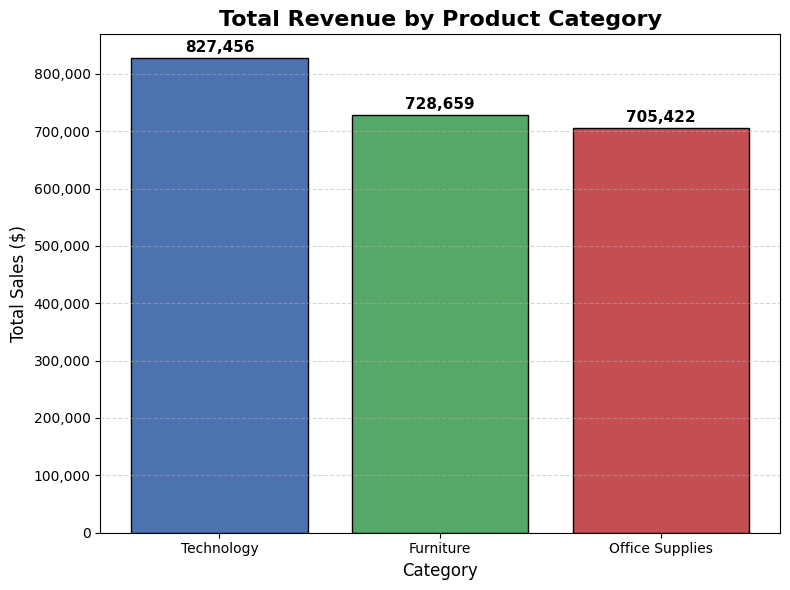

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(8,6))
bars = plt.bar(
    category_sales.index,
    category_sales.values,
    color=["#4C72B0", "#55A868", "#C44E52"],
    edgecolor="black",
    linewidth=1
)

plt.title("Total Revenue by Product Category",
          fontsize=16,
          fontweight="bold")

plt.xlabel("Category", fontsize=12)
plt.ylabel("Total Sales ($)", fontsize=12)

# Add Grid
plt.grid(axis='y',
         linestyle='--',
         alpha=0.5)

# Format Y-axis with commas
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{int(x):,}")
)

# Add value labels above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 10000,
        f"{height:,.0f}",
        ha='center',
        fontsize=11,
        fontweight='bold'
    )
plt.savefig(
    "charts/category_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.tight_layout()
plt.show()

### Observation
The **Technology** category generated the highest total revenue (₹8,27,455.87), followed by Furniture (₹7,28,658.58) and Office Supplies (₹7,05,422.33). This indicates that Technology products contributed the most to the company's overall sales during the four-year period and may represent the highest-value product category for inventory and business planning.

## Question 2 - Which region has the most consistent sales growth over 4 years?

In [18]:
# Create Quarter Period (e.g., 2015Q1, 2015Q2)

df_clean["Quarter Period"] = df_clean["Order Date"].dt.to_period("Q")
# Quarterly Sales by Region
region_quarterly = (
    df_clean.groupby(["Quarter Period", "Region"])["Sales"]
            .sum()
            .reset_index()
)
region_quarterly.head()

,Quarter Period,Region,Sales
0,2015Q1,Central,8594.7420
1,2015Q1,East,6094.1260
2,2015Q1,South,44236.9510
3,2015Q1,West,15005.5770
4,2015Q2,Central,17130.9686


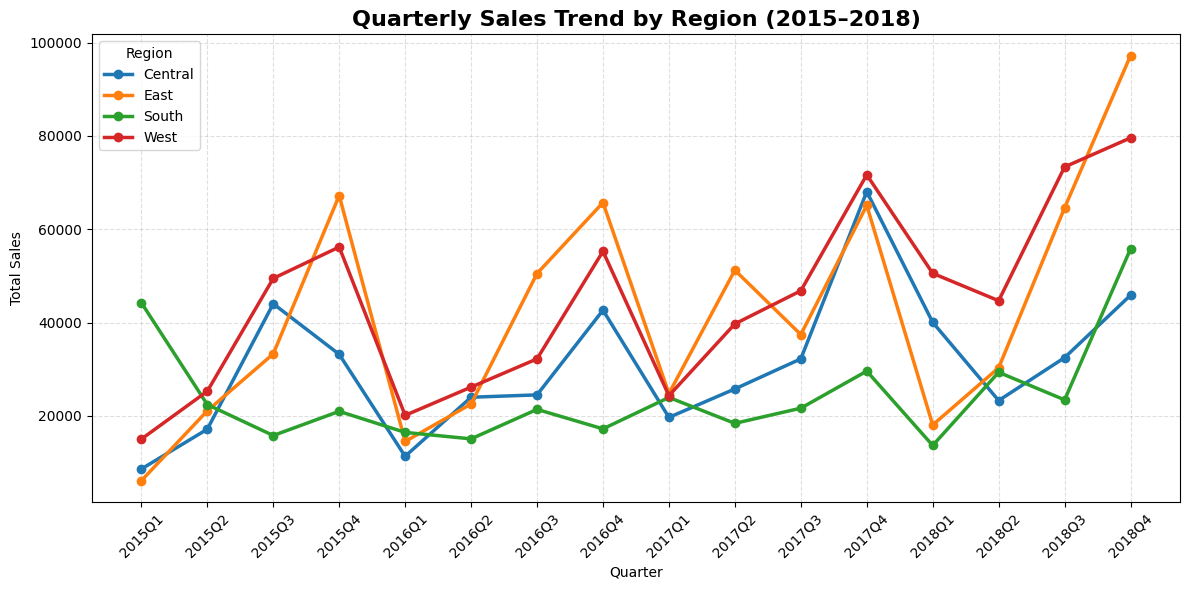

In [19]:
plt.figure(figsize=(12,6))

# Plot each region separately
for region in region_quarterly["Region"].unique():

    region_data = region_quarterly[
        region_quarterly["Region"] == region
    ]

    plt.plot(
        region_data["Quarter Period"].astype(str),
        region_data["Sales"],
        marker="o",
        linewidth=2.5,
        label=region
    )

plt.title(
    "Quarterly Sales Trend by Region (2015–2018)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Quarter")
plt.ylabel("Total Sales")

plt.grid(alpha=0.4, linestyle="--")

plt.legend(title="Region")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig(
    "charts/quarterly_sales_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Observation: 
The **West** region demonstrates the **most consistent sales growth** over the four-year period, showing a relatively steady upward trend despite normal quarterly fluctuations. The **East** region records the highest sales peaks, particularly during the fourth quarter of each year, but also experiences sharper declines in earlier quarters, indicating stronger seasonal variation. The **South** region consistently reports lower sales compared to the other regions, while the **Central** region maintains moderate and relatively stable performance throughout the study period.

## Question 3 - What is the average time between Order Date and Ship Date — and does it vary by region?

In [20]:
# Calculate Shipping Time (in Days)

df_clean["Shipping Days"] = (
    df_clean["Ship Date"] - df_clean["Order Date"]
).dt.days
df_clean[["Order Date", "Ship Date", "Shipping Days"]].head()

,Order Date,Ship Date,Shipping Days
0,2017-11-08,2017-11-11,3
1,2017-11-08,2017-11-11,3
2,2017-06-12,2017-06-16,4
3,2016-10-11,2016-10-18,7
4,2016-10-11,2016-10-18,7


In [21]:
# Overall Average Shipping Time

average_shipping_time = df_clean["Shipping Days"].mean()

print(f"Average Shipping Time: {average_shipping_time:.2f} days")

Average Shipping Time: 3.96 days


In [22]:
# Average Shipping Time by Region

shipping_by_region = (
    df_clean.groupby("Region")["Shipping Days"]
            .mean()
            .sort_values(ascending=False)
)

shipping_by_region

Region
Central    4.065876
South      3.961202
West       3.930255
East       3.910233
Name: Shipping Days, dtype: float64

## Observation:
The average shipping time is approximately 3.96 days across all orders. Although the Central region has the highest average shipping time (4.07 days) and the East region has the lowest (3.91 days), the difference is only about 0.16 days (around 4 hours). Therefore, shipping performance is fairly consistent across all regions, with no significant regional variation.

## Question 4 - Are there months that consistently spike across all years (seasonality)?

In [23]:
# Prepare data for the monthly sales heatmap

seasonality_data = df_clean.copy()

seasonality_data["Year"] = seasonality_data["Order Date"].dt.year
seasonality_data["Month Name"] = seasonality_data["Order Date"].dt.month_name()

seasonality_data = (
    seasonality_data
    .groupby(["Year", "Month Name"], as_index=False)["Sales"]
    .sum()
)

In [24]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

seasonality_data["Month Name"] = pd.Categorical(
    seasonality_data["Month Name"],
    categories=month_order,
    ordered=True
)

seasonality_data = seasonality_data.sort_values(
    ["Year", "Month Name"]
)

In [25]:
seasonality_data.head(12)

,Year,Month Name,Sales
4,2015,January,14205.7070
3,2015,February,4519.8920
7,2015,March,55205.7970
0,2015,April,27906.8550
8,2015,May,23644.3030
6,2015,June,34322.9356
5,2015,July,33781.5430
1,2015,August,27117.5365
11,2015,September,81623.5268
10,2015,October,31453.3930


In [26]:
# Create Pivot Table for Heatmap

seasonality_pivot = seasonality_data.pivot(
    index="Month Name",
    columns="Year",
    values="Sales"
)

seasonality_pivot

Year,2015,2016,2017,2018
Month Name,,,,
January,14205.7070,18066.9576,18542.4910,43476.4740
February,4519.8920,11951.4110,22978.8150,19920.9974
March,55205.7970,32339.3184,51165.0590,58863.4128
April,27906.8550,34154.4685,38679.7670,35541.9101
May,23644.3030,29959.5305,56656.9080,43825.9822
June,34322.9356,23599.3740,39724.4860,48190.7277
July,33781.5430,28608.2590,38320.7830,44825.1040
August,27117.5365,36818.3422,30542.2003,62837.8480
September,81623.5268,63133.6060,69193.3909,86152.8880


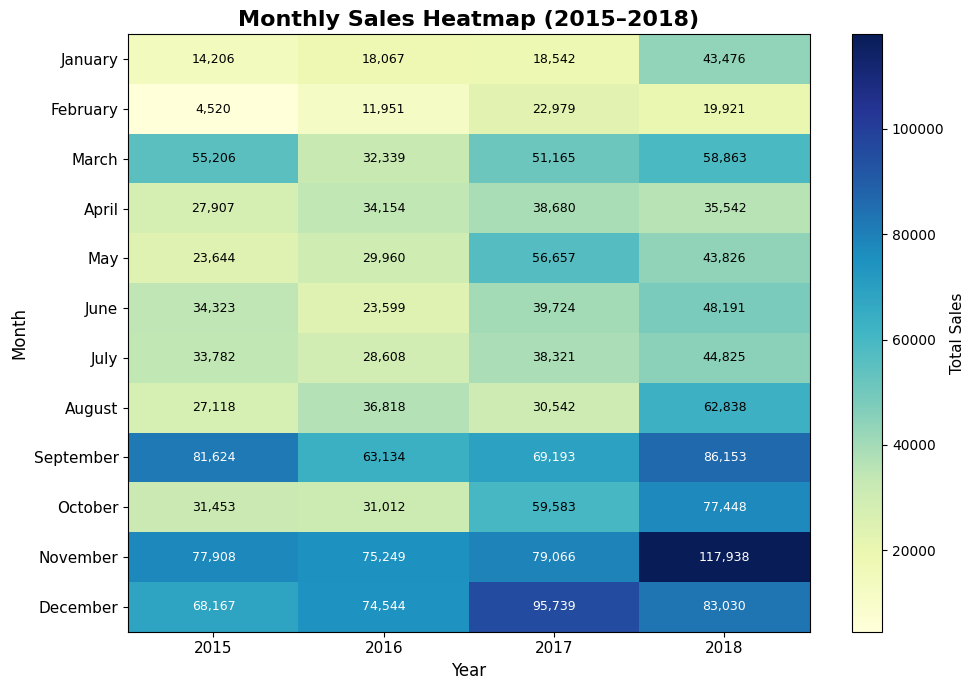

In [27]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 7))

# Draw Heatmap
heatmap = plt.imshow(
    seasonality_pivot,
    cmap="YlGnBu",
    aspect="auto"
)

# X-axis (Years)
plt.xticks(
    ticks=np.arange(len(seasonality_pivot.columns)),
    labels=seasonality_pivot.columns,
    fontsize=11
)

# Y-axis (Months)
plt.yticks(
    ticks=np.arange(len(seasonality_pivot.index)),
    labels=seasonality_pivot.index,
    fontsize=11
)

# Add values inside each cell
max_value = seasonality_pivot.values.max()

for i in range(len(seasonality_pivot.index)):
    for j in range(len(seasonality_pivot.columns)):
        value = seasonality_pivot.iloc[i, j]

        plt.text(
            j,
            i,
            f"{value:,.0f}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if value > max_value * 0.55 else "black"
        )

# Color Bar
cbar = plt.colorbar(heatmap)
cbar.set_label("Total Sales", fontsize=11)

# Labels and Title
plt.title(
    "Monthly Sales Heatmap (2015–2018)",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Month", fontsize=12)

# Save Figure
plt.savefig(
    "charts/monthly_sales_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

### Observation
The heatmap reveals a clear seasonal sales pattern across all four years. Sales consistently peak during **September, November, and December**, with **November** recording the highest sales in most years. In contrast, **January and February** show comparatively lower sales. The darker colors in 2018 also indicate an overall increase in sales compared to previous years, suggesting both business growth and recurring end-of-year seasonal demand.

## Task 1 Summary

### Key Findings
- Technology generated the highest total revenue across all product categories.
- The West region demonstrated the most consistent sales growth over the four-year period.
- The average shipping time was approximately 3.96 days, with minimal variation across regions.
- Sales exhibited a clear seasonal pattern, with September, November, and December consistently recording higher sales, while January and February showed comparatively lower demand.

## Task 2 — Time Series Analysis & Decomposition

In [28]:
monthly_sales.head()
monthly_sales.info()
monthly_sales.tail()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Order Date  48 non-null     datetime64[ns]
 1   Sales       48 non-null     float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 896.0 bytes


,Order Date,Sales
43,2018-08-31,62837.8480
44,2018-09-30,86152.8880
45,2018-10-31,77448.1312
46,2018-11-30,117938.1550
47,2018-12-31,83030.3888


In [29]:
# Create a copy so the original monthly_sales remains unchanged
monthly_ts = monthly_sales.copy()

# Set Order Date as the index
monthly_ts.set_index('Order Date', inplace=True)

# Ensure chronological order
monthly_ts.sort_index(inplace=True)

# Display the first few rows
monthly_ts.head()

,Sales
Order Date,
2015-01-31,14205.707
2015-02-28,4519.892
2015-03-31,55205.797
2015-04-30,27906.855
2015-05-31,23644.303


In [30]:
monthly_ts.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 48 entries, 2015-01-31 to 2018-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Sales   48 non-null     float64
dtypes: float64(1)
memory usage: 768.0 bytes


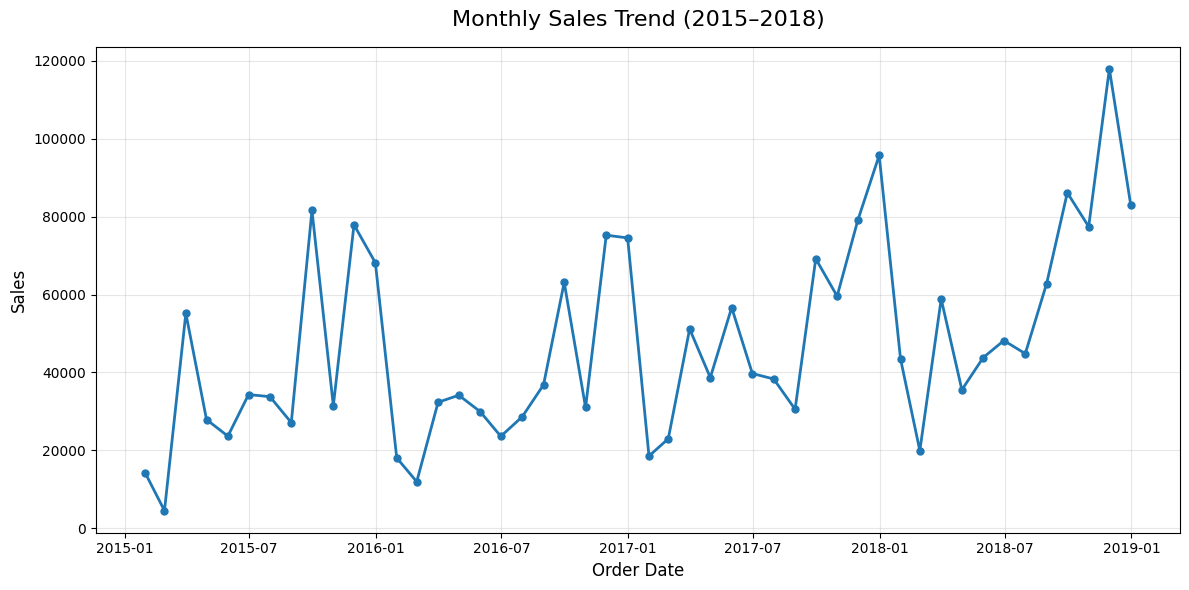

In [31]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_ts.index,
    monthly_ts['Sales'],
    linewidth=2,
    marker='o',
    markersize=5
)

plt.title('Monthly Sales Trend (2015–2018)', fontsize=16, pad=15)
plt.xlabel('Order Date', fontsize=12)
plt.ylabel('Sales', fontsize=12)

plt.grid(True, alpha=0.3)

plt.tight_layout()

# Save the figure
plt.savefig('charts/monthly_sales_trend.png', dpi=300)

plt.show()

In [32]:
import statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(
    monthly_ts['Sales'],
    model='additive',
    period=12
)

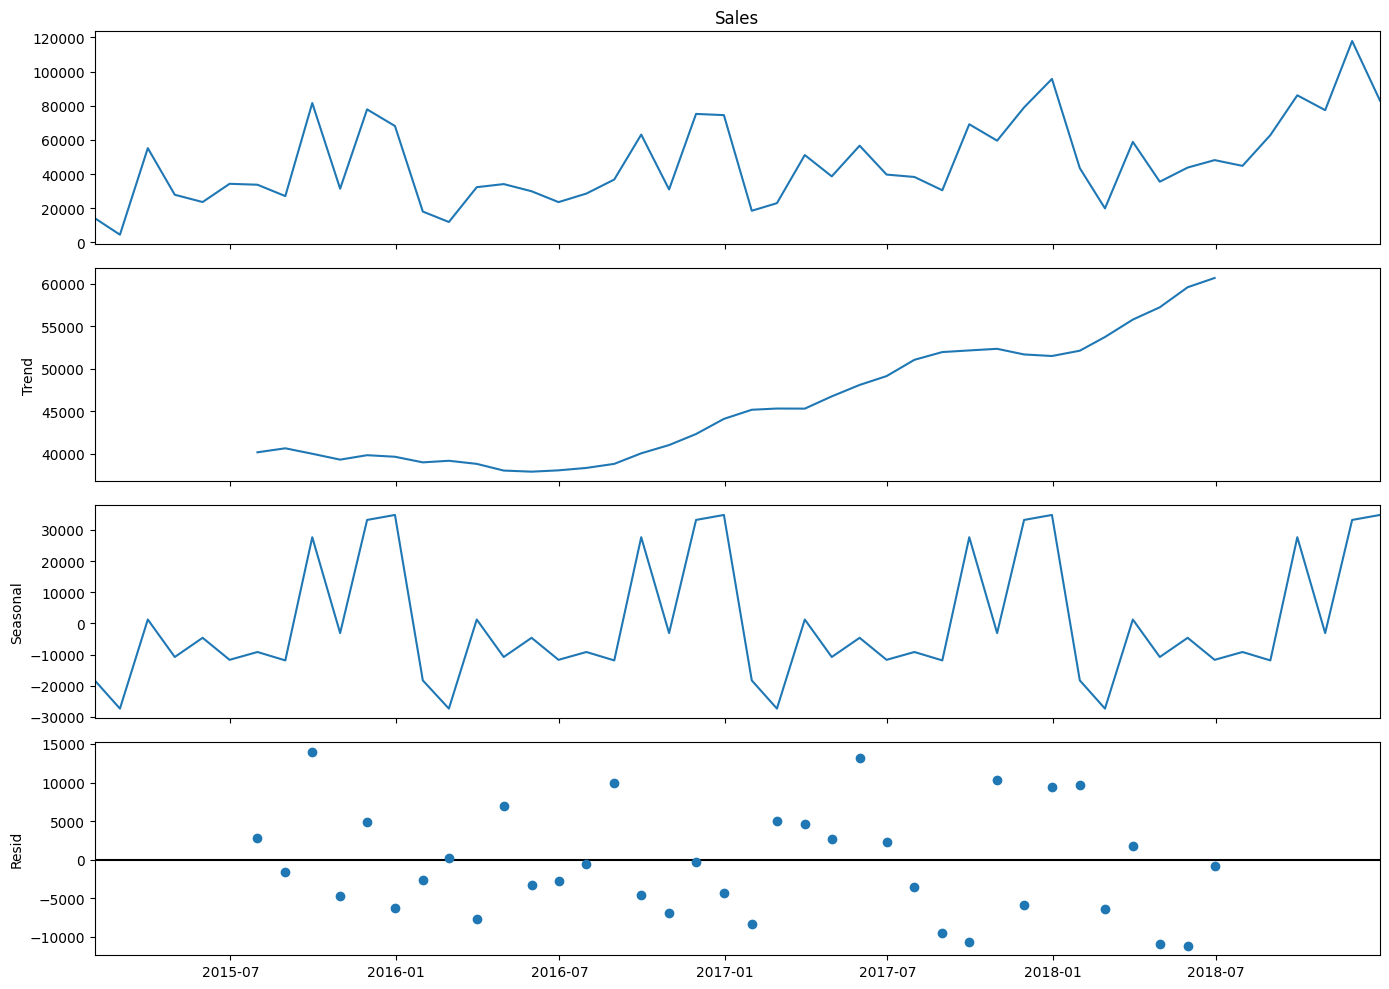

In [33]:
fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.tight_layout()
plt.savefig(
    "charts/time_series_decomposition.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Observation 1 – Trend
The trend component shows a gradual upward movement in monthly sales over the four-year period. After remaining relatively stable during the initial period, sales increase steadily from 2016 onwards, indicating sustained business growth.

## Observation 2 – Seasonality
The seasonal component exhibits a clear and repeating yearly pattern, indicating strong seasonality. Several months consistently contribute positively or negatively to sales each year, suggesting recurring seasonal buying behavior.

In [34]:
# Display the months with the largest absolute residuals
residuals = decomposition.resid.dropna()

largest_residuals = residuals.abs().sort_values(ascending=False).head(5)

largest_residuals

Order Date
2015-09-30    13970.933082
2017-05-31    13193.079793
2018-05-31    11157.549320
2018-04-30    10916.959724
2017-09-30    10642.715643
Name: resid, dtype: float64

In [35]:
monthly_ts.loc[largest_residuals.index]

,Sales
Order Date,
2015-09-30,81623.5268
2017-05-31,56656.9080
2018-05-31,43825.9822
2018-04-30,35541.9101
2017-09-30,69193.3909


In [36]:
print(monthly_ts)

                  Sales
Order Date             
2015-01-31   14205.7070
2015-02-28    4519.8920
2015-03-31   55205.7970
2015-04-30   27906.8550
2015-05-31   23644.3030
2015-06-30   34322.9356
2015-07-31   33781.5430
2015-08-31   27117.5365
2015-09-30   81623.5268
2015-10-31   31453.3930
2015-11-30   77907.6607
2015-12-31   68167.0585
2016-01-31   18066.9576
2016-02-29   11951.4110
2016-03-31   32339.3184
2016-04-30   34154.4685
2016-05-31   29959.5305
2016-06-30   23599.3740
2016-07-31   28608.2590
2016-08-31   36818.3422
2016-09-30   63133.6060
2016-10-31   31011.7375
2016-11-30   75249.3995
2016-12-31   74543.6012
2017-01-31   18542.4910
2017-02-28   22978.8150
2017-03-31   51165.0590
2017-04-30   38679.7670
2017-05-31   56656.9080
2017-06-30   39724.4860
2017-07-31   38320.7830
2017-08-31   30542.2003
2017-09-30   69193.3909
2017-10-31   59583.0330
2017-11-30   79066.4958
2017-12-31   95739.1210
2018-01-31   43476.4740
2018-02-28   19920.9974
2018-03-31   58863.4128
2018-04-30   355

## Observation 3 – Residual Noise
The residual component is centered around zero for most observations, indicating that the trend and seasonal components explain a significant portion of the variation in sales. The highest residual noise was observed in September 2015, May 2017, May 2018, April 2018, and September 2017, suggesting unusual events or external factors that were not captured by the decomposition model.

## Observation 4 – Overall Interpretation
Overall, the decomposition reveals that monthly sales are driven by a combination of a positive long-term growth trend and a strong seasonal pattern, while only a small number of months exhibit unusually high unexplained variation.

## Stationarity Analysis using the Augmented Dickey-Fuller (ADF) Test
**means that the statistical properties of a time series, such as its average and variance, remain relatively constant over time. A stationary series does not exhibit a persistent upward or downward trend and is generally more suitable for time series forecasting models.**

In [37]:
from statsmodels.tsa.stattools import adfuller
# Performing Augmented Dickey-Fuller (ADF) Test
adf_result = adfuller(monthly_ts["Sales"])

print("ADF Statistic :", adf_result[0])
print("p-value       :", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(f"   {key}: {value}")

ADF Statistic : -4.416136761430768
p-value       : 0.00027791039276670677
Critical Values:
   1%: -3.5778480370438146
   5%: -2.925338105429433
   10%: -2.6007735310095064


### Interpretation of the ADF Test

The Augmented Dickey-Fuller (ADF) Test was performed to determine whether the monthly sales time series is stationary.

A stationary time series has statistical properties such as the mean and variance that remain relatively constant over time. Many forecasting models perform better when the input data is stationary.

The ADF test produced:

- **ADF Statistic:** -4.4161
- **p-value:** 0.000278

Since the p-value is less than the significance level of 0.05, the null hypothesis of non-stationarity is rejected. Therefore, the monthly sales series is considered **stationary**.

## First-Order Differencing (Demonstration)

Since the original time series is already stationary according to the ADF Test, differencing is **not required** for further analysis.

However, first-order differencing is applied below for demonstration purposes to illustrate a common preprocessing technique used in time series forecasting when a series is non-stationary.

In [38]:
# Apply first-order differencing
monthly_diff = monthly_ts["Sales"].diff()

# Remove the first NaN value created by differencing
monthly_diff = monthly_diff.dropna()

# Display first few values
monthly_diff.head()

Order Date
2015-02-28    -9685.8150
2015-03-31    50685.9050
2015-04-30   -27298.9420
2015-05-31    -4262.5520
2015-06-30    10678.6326
Name: Sales, dtype: float64

### First-Order Differenced Series

The graph below shows the first-order differenced monthly sales series. Differencing removes the previous observation from the current observation, helping eliminate long-term trends and making the series more stable over time.

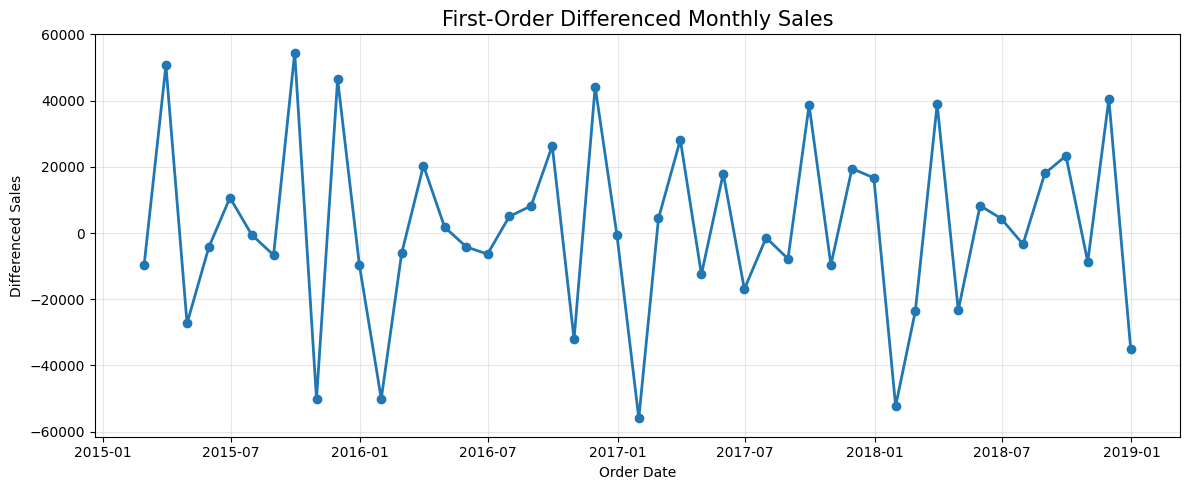

In [39]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_diff.index,
    monthly_diff,
    marker='o',
    linewidth=2
)

plt.title("First-Order Differenced Monthly Sales", fontsize=15)
plt.xlabel("Order Date")
plt.ylabel("Differenced Sales")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "charts/differenced_monthly_sales.png",
    dpi=300
)

plt.show()

### ADF Test on the Differenced Series

After applying first-order differencing, the Augmented Dickey-Fuller (ADF) Test is performed again to verify whether the transformed series is stationary.

In [40]:
# Perform ADF Test on differenced series
adf_diff = adfuller(monthly_diff)

print("ADF Statistic :", adf_diff[0])
print("p-value       :", adf_diff[1])
print("Critical Values:")

for key, value in adf_diff[4].items():
    print(f"   {key}: {value}")

ADF Statistic : -8.727061830353279
p-value       : 3.2669175472794505e-14
Critical Values:
   1%: -3.626651907578875
   5%: -2.9459512825788754
   10%: -2.6116707716049383


### Interpretation of the Differenced Series

The ADF Test on the differenced series produced:

- **ADF Statistic:** -8.7271
- **p-value:** 3.27 × 10⁻¹⁴

The p-value is significantly less than 0.05, indicating strong evidence against the null hypothesis of non-stationarity.

Although the original monthly sales series was already stationary, first-order differencing further stabilized the data by removing remaining trend effects. The differenced series fluctuates around a relatively constant level, confirming its suitability for time series modeling.

## Task 3 — Sales Forecasting using 3 Different Models

## Model 1 — SARIMA (Statistical Model)

In [41]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from sklearn.metrics import mean_absolute_error, mean_squared_error

In [42]:
# Make a copy of the time series
ts = monthly_ts.copy()

# Ensure datetime index
ts.index = pd.to_datetime(ts.index)

# Display first few rows
ts.head()

,Sales
Order Date,
2015-01-31,14205.707
2015-02-28,4519.892
2015-03-31,55205.797
2015-04-30,27906.855
2015-05-31,23644.303


In [43]:
# Split into train and test sets

train = ts.iloc[:-3]
test = ts.iloc[-3:]
print("Training observations :", len(train))
print("Testing observations  :", len(test))

Training observations : 45
Testing observations  : 3


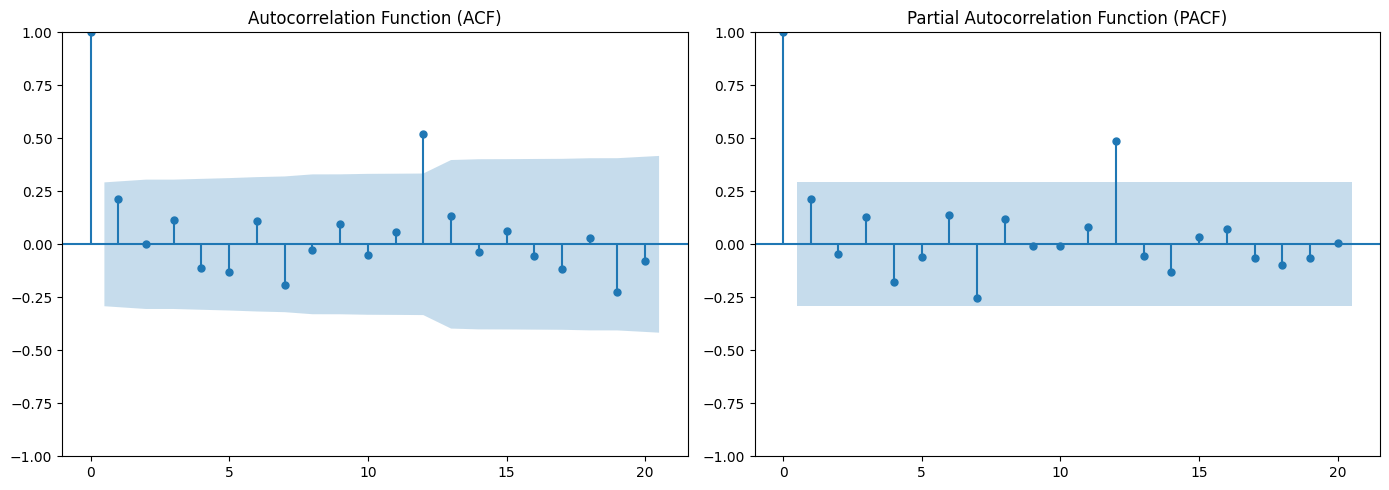

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

plot_acf(train, ax=axes[0], lags=20)
axes[0].set_title("Autocorrelation Function (ACF)")
plot_pacf(train, ax=axes[1], lags=20, method='ywm')
axes[1].set_title("Partial Autocorrelation Function (PACF)")
plt.tight_layout()
plt.show()

In [45]:
# Build the SARIMA model
sarima_model = SARIMAX(
    train,
    order=(2,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
)
ts = monthly_ts.copy()
ts.index = pd.to_datetime(ts.index)
ts = ts.asfreq('ME')
# Train the model
sarima_fit = sarima_model.fit()

# Display model summary
print(sarima_fit.summary())

C:\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
C:\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
C:\Python310\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


                                     SARIMAX Results                                      
Dep. Variable:                              Sales   No. Observations:                   45
Model:             SARIMAX(2, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -193.003
Date:                            Wed, 08 Jul 2026   AIC                            398.007
Time:                                    10:08:27   BIC                            403.349
Sample:                                01-31-2015   HQIC                           398.743
                                     - 09-30-2018                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -1.2970      0.350     -3.704      0.000      -1.983      -0.611
ar.L2         -0.7001      0.337   

In [46]:
# Forecast the next 3 months
sarima_forecast = sarima_fit.get_forecast(steps=3)

# Predicted values
forecast_mean = sarima_forecast.predicted_mean

# Confidence intervals
forecast_ci = sarima_forecast.conf_int()

print(forecast_mean)

2018-10-31     58533.923415
2018-11-30    102800.019902
2018-12-31     95467.637045
Freq: ME, Name: predicted_mean, dtype: float64


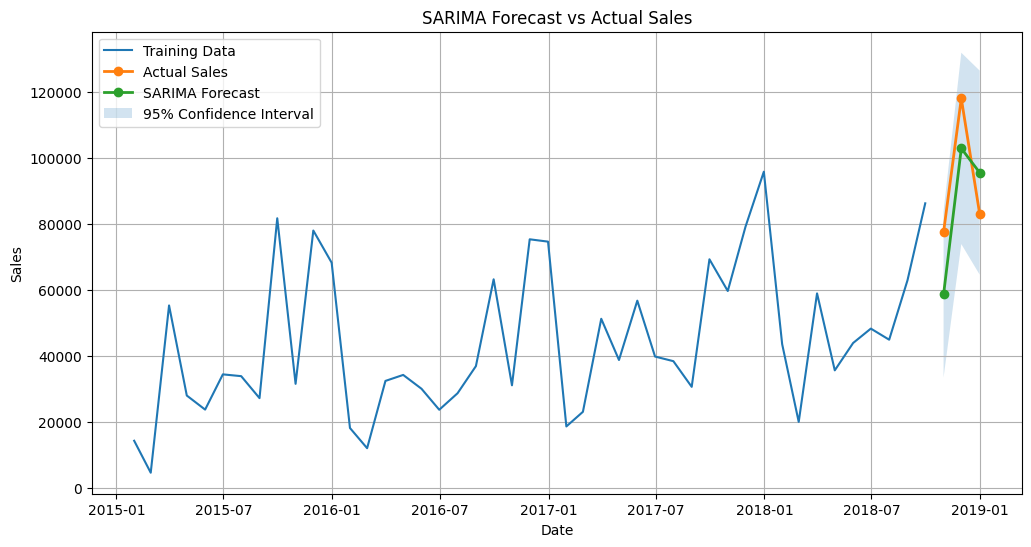

In [47]:
plt.figure(figsize=(12,6))

# Training data
plt.plot(train.index, train['Sales'], label='Training Data')

# Actual test data
plt.plot(test.index, test['Sales'], label='Actual Sales',
         marker='o', linewidth=2)

# Forecast
plt.plot(test.index, forecast_mean,
         label='SARIMA Forecast',
         marker='o', linewidth=2)

# Confidence interval
plt.fill_between(
    test.index,
    forecast_ci.iloc[:,0],
    forecast_ci.iloc[:,1],
    alpha=0.2,
    label='95% Confidence Interval'
)

plt.title("SARIMA Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Actual values
y_true = test['Sales']

# Predicted values
y_pred = forecast_mean

# Metrics
mae_sarima = mean_absolute_error(y_true, y_pred)
rmse_sarima = np.sqrt(mean_squared_error(y_true, y_pred))
mape_sarima = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print(f"MAE  : {mae_sarima:.2f}")
print(f"RMSE : {rmse_sarima:.2f}")
print(f"MAPE : {mape_sarima:.2f}%")

MAE  : 15496.53
RMSE : 15722.55
MAPE : 17.41%


### Preliminary SARIMA single-holdout check

This earlier three-month split was useful for learning the model, but it is too small to decide the final winner. The final model comparison is the expanding-window backtest added below.


In [49]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Candidate SARIMA configurations
models = [
    ((1,1,1), (1,1,1,12)),
    ((0,1,1), (0,1,1,12)),
    ((1,1,0), (1,1,0,12)),
    ((2,1,1), (1,1,1,12)),
    ((1,1,2), (1,1,1,12))
]

results = []

for order, seasonal_order in models:

    try:
        model = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted = model.fit(disp=False)

        forecast = fitted.get_forecast(steps=3).predicted_mean

        mae = mean_absolute_error(test['Sales'], forecast)
        rmse = np.sqrt(mean_squared_error(test['Sales'], forecast))
        mape = np.mean(np.abs((test['Sales'] - forecast) / test['Sales'])) * 100

        results.append([
            order,
            seasonal_order,
            mae,
            rmse,
            mape
        ])

    except Exception as e:
        print(f"Model {order} {seasonal_order} failed:", e)

# Display results
results_df = pd.DataFrame(
    results,
    columns=["Order", "Seasonal Order", "MAE", "RMSE", "MAPE"]
)

results_df.sort_values("MAE")

C:\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
C:\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
C:\Python310\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
C:\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency ME will be used.
  self._init_dates(dates, freq)
C:\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred f

,Order,Seasonal Order,MAE,RMSE,MAPE
3,"(2, 1, 1)","(1, 1, 1, 12)",15496.530376,15722.547867,17.412194
2,"(1, 1, 0)","(1, 1, 0, 12)",17148.744457,18901.350130,18.649389
0,"(1, 1, 1)","(1, 1, 1, 12)",19244.485341,19950.070418,20.526432
1,"(0, 1, 1)","(0, 1, 1, 12)",19299.922668,20205.764079,20.362136
4,"(1, 1, 2)","(1, 1, 1, 12)",19478.257342,20074.162408,21.137706


**Preliminary result only:** The selected configuration is chosen within the original single holdout. See the final rolling-origin comparison below for model selection.


## Preliminary SARIMA observations

These observations describe one three-month holdout only. The larger, time-ordered backtest below replaces this result for the final recommendation.


## Model 2 — Facebook Prophet (Industry-standard Forecasting Tool)

In [50]:
!pip install prophet


[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [51]:
from prophet import Prophet

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import matplotlib.pyplot as plt
import numpy as np

C:\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [52]:
# Prepare data for Prophet
prophet_df = monthly_ts.reset_index()
prophet_df.columns = ['ds', 'y']
prophet_df.head()

,ds,y
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


In [53]:
train_prophet = prophet_df.iloc[:-3]

test_prophet = prophet_df.iloc[-3:]

print("Training observations :", len(train_prophet))
print("Testing observations  :", len(test_prophet))

Training observations : 45
Testing observations  : 3


In [54]:
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

prophet_model.fit(train_prophet)

10:08:33 - cmdstanpy - INFO - Chain [1] start processing
10:08:34 - cmdstanpy - INFO - Chain [1] done processing


In [55]:
future = prophet_model.make_future_dataframe(
    periods=3,
    freq='M'
)

forecast = prophet_model.predict(future)

forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail()

C:\Python310\lib\site-packages\prophet\forecaster.py:1875: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(


,ds,yhat,yhat_lower,yhat_upper
43,2018-08-31,47271.558236,38774.036643,55233.271930
44,2018-09-30,86613.953316,78790.458866,95469.491798
45,2018-10-31,51318.943858,43401.070800,59373.002705
46,2018-11-30,90325.654784,82732.769267,99322.285035
47,2018-12-31,90041.084479,82005.566901,97869.136560


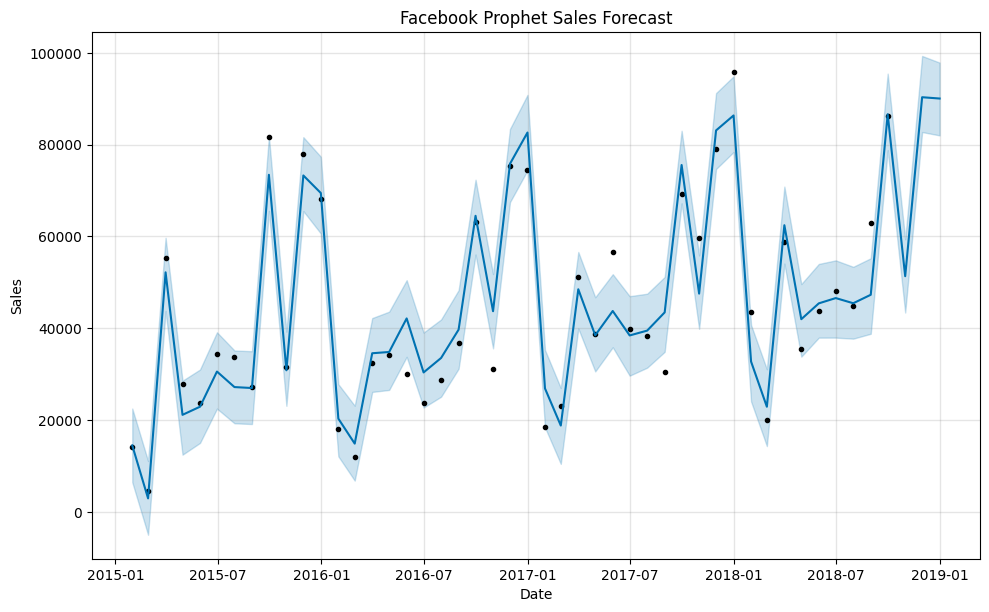

In [56]:
fig = prophet_model.plot(forecast)

plt.title("Facebook Prophet Sales Forecast")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.show()

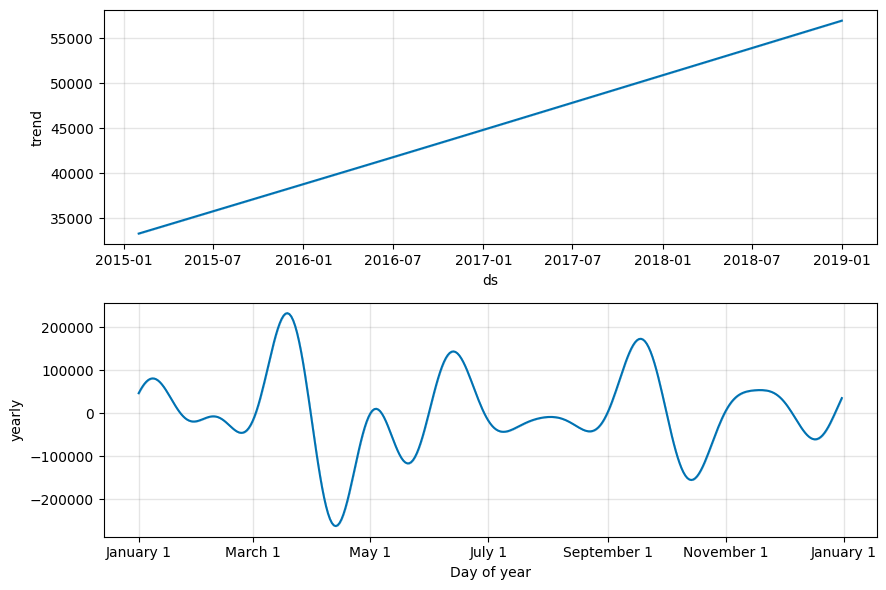

In [57]:
fig2 = prophet_model.plot_components(forecast)

plt.show()

In [58]:
forecast_test = forecast[['ds', 'yhat']].tail(3)

comparison = test_prophet.merge(
    forecast_test,
    on='ds'
)

comparison

,ds,y,yhat
0,2018-10-31,77448.1312,51318.943858
1,2018-11-30,117938.1550,90325.654784
2,2018-12-31,83030.3888,90041.084479


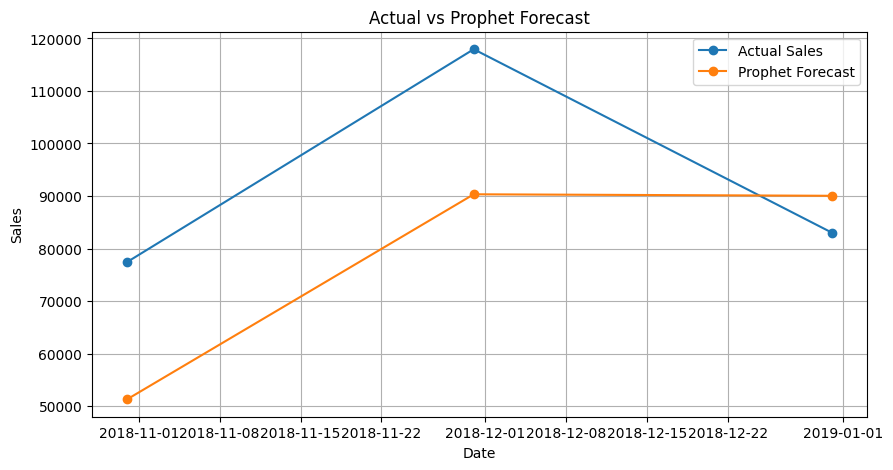

In [59]:
plt.figure(figsize=(10,5))

plt.plot(
    comparison['ds'],
    comparison['y'],
    marker='o',
    label='Actual Sales'
)

plt.plot(
    comparison['ds'],
    comparison['yhat'],
    marker='o',
    label='Prophet Forecast'
)

plt.title("Actual vs Prophet Forecast")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.legend()

plt.grid(True)

plt.show()

In [60]:
mae_prophet = mean_absolute_error(
    comparison['y'],
    comparison['yhat']
)

rmse_prophet = np.sqrt(
    mean_squared_error(
        comparison['y'],
        comparison['yhat']
    )
)

mape_prophet = np.mean(
    np.abs(
        (comparison['y'] - comparison['yhat'])
        / comparison['y']
    )
) * 100

print(f"MAE  : {mae_prophet:.2f}")
print(f"RMSE : {rmse_prophet:.2f}")
print(f"MAPE : {mape_prophet:.2f}%")

MAE  : 20250.79
RMSE : 22318.41
MAPE : 21.86%


## Preliminary Prophet observations

These metrics come from one three-month holdout. Use the rolling-origin comparison below for the fair final model comparison.


## Model 3 — XGBoost

In [61]:
!pip install xgboost
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [62]:
ts_ml = monthly_ts.copy().reset_index()
ts_ml.head()

,Order Date,Sales
0,2015-01-31,14205.707
1,2015-02-28,4519.892
2,2015-03-31,55205.797
3,2015-04-30,27906.855
4,2015-05-31,23644.303


In [ ]:
# Lag Features
ts_ml['Lag_1'] = ts_ml['Sales'].shift(1)
ts_ml['Lag_2'] = ts_ml['Sales'].shift(2)
ts_ml['Lag_3'] = ts_ml['Sales'].shift(3)

# 3-Month Rolling Mean
ts_ml['Rolling_Mean_3'] = ts_ml['Sales'].shift(1).rolling(window=3).mean()

# Calendar Features
ts_ml['Month'] = ts_ml['Order Date'].dt.month
ts_ml['Quarter'] = ts_ml['Order Date'].dt.quarter

# Season Feature
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Autumn'

ts_ml['Season'] = ts_ml['Month'].apply(get_season)

# One-hot encode Season
ts_ml = pd.get_dummies(ts_ml, columns=['Season'], drop_first=True)

# Remove missing rows
ts_ml = ts_ml.dropna()

ts_ml.head()

In [64]:
X = ts_ml.drop(columns=['Order Date', 'Sales'])
y = ts_ml['Sales']

In [65]:
X_train = X.iloc[:-3]
y_train = y.iloc[:-3]

test_dates = ts_ml['Order Date'].iloc[-3:].reset_index(drop=True)
y_test = y.iloc[-3:].reset_index(drop=True)

In [66]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

xgb_model.fit(X_train, y_train)

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [67]:
# Forecast the held-out months one at a time.
# Each prediction is fed into history before forecasting the next month.
forecast_history = monthly_ts['Sales'].iloc[:-3].astype(float).tolist()
xgb_predictions = []

for next_date in test_dates:
    month = next_date.month
    season = get_season(month)

    feature_row = {
        'Lag_1': forecast_history[-1],
        'Lag_2': forecast_history[-2],
        'Lag_3': forecast_history[-3],
        'Rolling_Mean_3': np.mean(forecast_history[-3:]),
        'Month': month,
        'Quarter': next_date.quarter,
        'Season_Spring': int(season == 'Spring'),
        'Season_Summer': int(season == 'Summer'),
        'Season_Winter': int(season == 'Winter')
    }

    X_next = pd.DataFrame([feature_row]).reindex(
        columns=X_train.columns,
        fill_value=0
    )
    y_pred = float(xgb_model.predict(X_next)[0])
    xgb_predictions.append(y_pred)
    forecast_history.append(y_pred)

xgb_predictions = np.array(xgb_predictions)

print("Predictions:")
print(xgb_predictions)

Predictions:
[71239.265625  86572.8828125 65806.59375 ]


In [68]:
# Prophet is selected for deployment by the rolling-origin comparison below.
# This XGBoost cell is retained as a comparison candidate; it does not save a production model.


['models/best_model.pkl']

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    ts_ml['Order Date'].iloc[-3:],
    y_test,
    marker='o',
    linewidth=2,
    label='Actual Sales'
)

plt.plot(
    ts_ml['Order Date'].iloc[-3:],
    xgb_predictions,
    marker='o',
    linewidth=2,
    label='XGBoost Prediction'
)

plt.title("Actual vs XGBoost Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

In [70]:
mae_xgb = mean_absolute_error(y_test, xgb_predictions)

rmse_xgb = np.sqrt(
    mean_squared_error(y_test, xgb_predictions)
)

mape_xgb = np.mean(
    np.abs((y_test - xgb_predictions) / y_test)
) * 100

print(f"MAE  : {mae_xgb:.2f}")
print(f"RMSE : {rmse_xgb:.2f}")
print(f"MAPE : {mape_xgb:.2f}%")

MAE  : 18265.98
RMSE : 20968.15
MAPE : 18.45%


In [71]:
import pandas as pd

metrics_df = pd.DataFrame({
    "Model": ["XGBoost"],
    "MAE": [mae_xgb],
    "RMSE": [rmse_xgb],
    "MAPE": [mape_xgb]
})

metrics_df.to_csv("saved_outputs/model_metrics.csv", index=False)

In [ ]:
comparison_xgb = pd.DataFrame({
    "Date": ts_ml['Order Date'].iloc[-3:].values,
    "Actual Sales": y_test.values,
    "Predicted Sales": xgb_predictions
})

comparison_xgb

## Preliminary single-holdout observation

This three-month comparison is kept for the model walkthrough. The final recommendation is based on the common expanding-window backtest below, which evaluates 24 unseen months per model.


In [ ]:
comparison_table = pd.DataFrame({
    "Model": ["SARIMA", "Prophet", "XGBoost"],
    "MAE": [
        round(mae_sarima, 2),
        round(mae_prophet, 2),
        round(mae_xgb, 2)
    ],
    "RMSE": [
        round(rmse_sarima, 2),
        round(rmse_prophet, 2),
        round(rmse_xgb, 2)
    ],
    "MAPE (%)": [
        round(mape_sarima, 2),
        round(mape_prophet, 2),
        round(mape_xgb, 2)
    ],
    "Forecast Month 1": [
        round(forecast_mean.iloc[0], 2),
        round(comparison['yhat'].iloc[0], 2),
        round(xgb_predictions[0], 2)
    ],
    "Forecast Month 2": [
        round(forecast_mean.iloc[1], 2),
        round(comparison['yhat'].iloc[1], 2),
        round(xgb_predictions[1], 2)
    ],
    "Forecast Month 3": [
        round(forecast_mean.iloc[2], 2),
        round(comparison['yhat'].iloc[2], 2),
        round(xgb_predictions[2], 2)
    ]
})

comparison_table.style.hide(axis="index")

## Final Recommendation

Use the expanding-window backtest below as the final model comparison. It evaluates all three models on the same 24 unseen months, in eight chronological three-month forecast windows.


## Final rolling-origin model comparison

This evaluation starts with 24 months of history, then forecasts the next three months. It advances by three months and repeats eight times. At each origin, each model sees only earlier months. SARIMA configuration selection uses AIC calculated on that fold's training history; Prophet fits only that history; XGBoost is trained only on available lagged rows and predicts recursively, feeding its own forecasts into the next step. Metrics are computed over the same 24 held-out months for all models.

The test months' actual sales are used only after forecasts are made, to calculate error. The saved prediction file keeps each fold's origin, actual, and predicted values for audit.


In [ ]:
import numpy as np
import pandas as pd
from prophet import Prophet
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the already aggregated monthly series from the earlier notebook cells.
_bt = monthly_ts["Sales"].astype(float).asfreq("ME").fillna(0)
_bt = _bt.sort_index()
_initial_train, _horizon, _step = 24, 3, 3
_sarima_candidates = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((0, 1, 1), (0, 1, 1, 12)),
    ((1, 1, 0), (1, 1, 0, 12)),
    ((2, 1, 1), (1, 1, 1, 12)),
    ((1, 1, 2), (1, 1, 1, 12)),
]

def _bt_season(month):
    if month in [12, 1, 2]: return "Winter"
    if month in [3, 4, 5]: return "Spring"
    if month in [6, 7, 8]: return "Summer"
    return "Autumn"

def _bt_xgb_features(series):
    frame = pd.DataFrame({"Sales": series.astype(float)})
    frame["Lag_1"] = frame["Sales"].shift(1)
    frame["Lag_2"] = frame["Sales"].shift(2)
    frame["Lag_3"] = frame["Sales"].shift(3)
    frame["Rolling_Mean_3"] = frame["Sales"].shift(1).rolling(3).mean()
    frame["Month"] = frame.index.month
    frame["Quarter"] = frame.index.quarter
    season = pd.get_dummies(pd.Series(frame.index.month, index=frame.index).map(_bt_season), prefix="Season", dtype=int)
    frame = pd.concat([frame, season], axis=1)
    cols = ["Lag_1", "Lag_2", "Lag_3", "Rolling_Mean_3", "Month", "Quarter", "Season_Spring", "Season_Summer", "Season_Winter"]
    return frame.reindex(columns=["Sales"] + cols, fill_value=0).dropna()

_backtest_rows = []
for _end in range(_initial_train, len(_bt) - _horizon + 1, _step):
    _train, _actual = _bt.iloc[:_end], _bt.iloc[_end:_end + _horizon]
    _origin = _train.index[-1]

    # SARIMA candidates are compared using training-only AIC, never test errors.
    _fits = []
    for _order, _seasonal in _sarima_candidates:
        try:
            _fit = SARIMAX(_train, order=_order, seasonal_order=_seasonal,
                           enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            _fits.append((_fit.aic, _order, _seasonal, _fit))
        except Exception:
            continue
    if not _fits:
        raise RuntimeError(f"No SARIMA candidate fitted at origin {_origin}")
    _, _order, _seasonal, _fit = min(_fits, key=lambda item: item[0])
    _sarima_pred = np.maximum(0, _fit.get_forecast(steps=_horizon).predicted_mean.to_numpy())

    _prophet_train = pd.DataFrame({"ds": _train.index, "y": _train.values})
    _prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False,
                       daily_seasonality=False, uncertainty_samples=0)
    _prophet.fit(_prophet_train)
    _prophet_pred = np.maximum(0, _prophet.predict(pd.DataFrame({"ds": _actual.index}))[
        "yhat"].to_numpy())

    _feature_data = _bt_xgb_features(_train)
    _xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
    _xgb.fit(_feature_data.drop(columns="Sales"), _feature_data["Sales"])
    _history = list(_train.values)
    _xgb_pred = []
    for _date in _actual.index:
        _season_row = _bt_season(_date.month)
        _row = {"Lag_1": _history[-1], "Lag_2": _history[-2], "Lag_3": _history[-3],
                "Rolling_Mean_3": np.mean(_history[-3:]), "Month": _date.month,
                "Quarter": _date.quarter, "Season_Spring": int(_season_row == "Spring"),
                "Season_Summer": int(_season_row == "Summer"), "Season_Winter": int(_season_row == "Winter")}
        _prediction = max(0.0, float(_xgb.predict(pd.DataFrame([_row]))[0]))
        _xgb_pred.append(_prediction)
        _history.append(_prediction)

    for _name, _pred in [("SARIMA", _sarima_pred), ("Prophet", _prophet_pred), ("XGBoost", _xgb_pred)]:
        for _date, _truth, _guess in zip(_actual.index, _actual.values, _pred):
            _backtest_rows.append({"Model": _name, "Origin": _origin, "Date": _date,
                                   "Actual": float(_truth), "Predicted": float(_guess),
                                   "SARIMA_Order": str(_order) if _name == "SARIMA" else ""})

_backtest = pd.DataFrame(_backtest_rows)
_backtest["Absolute_Error"] = (_backtest["Actual"] - _backtest["Predicted"]).abs()
_backtest["Squared_Error"] = (_backtest["Actual"] - _backtest["Predicted"]) ** 2
_backtest["Absolute_Percent_Error"] = _backtest["Absolute_Error"] / _backtest["Actual"].replace(0, np.nan) * 100
_model_metrics = (_backtest.groupby("Model").agg(
    MAE=("Absolute_Error", "mean"), RMSE=("Squared_Error", lambda x: np.sqrt(x.mean())),
    MAPE=("Absolute_Percent_Error", "mean"), Folds=("Origin", "nunique"), Forecasts=("Date", "size"))
    .sort_values("MAE").reset_index())
_model_metrics.to_csv("saved_outputs/model_metrics.csv", index=False)
_backtest.to_csv("saved_outputs/forecast_backtest_predictions.csv", index=False)
display(_model_metrics.round(2))


## Task 4 — Product Category & Region Level Forecasting

In [74]:
def xgb_forecast(data):
    """Train on earlier months and recursively forecast the final three months."""
    monthly = (data.groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
               .sum().reset_index().sort_values("Order Date"))

    def season(month):
        if month in [12, 1, 2]: return 1
        if month in [3, 4, 5]: return 2
        if month in [6, 7, 8]: return 3
        return 4

    monthly["Lag_1"] = monthly["Sales"].shift(1)
    monthly["Lag_2"] = monthly["Sales"].shift(2)
    monthly["Lag_3"] = monthly["Sales"].shift(3)
    monthly["Rolling_Mean_3"] = monthly["Sales"].shift(1).rolling(3).mean()
    monthly["Month"] = monthly["Order Date"].dt.month
    monthly["Quarter"] = monthly["Order Date"].dt.quarter
    monthly["Season"] = monthly["Month"].apply(season)
    monthly = monthly.dropna().reset_index(drop=True)

    feature_cols = ["Lag_1", "Lag_2", "Lag_3", "Rolling_Mean_3", "Month", "Quarter", "Season"]
    train = monthly.iloc[:-3]
    test_dates = monthly["Order Date"].iloc[-3:]
    model = XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
    model.fit(train[feature_cols], train["Sales"])

    history = list(monthly["Sales"].iloc[:-3].astype(float))
    predictions = []
    for date in test_dates:
        features = pd.DataFrame([{
            "Lag_1": history[-1], "Lag_2": history[-2], "Lag_3": history[-3],
            "Rolling_Mean_3": np.mean(history[-3:]), "Month": date.month,
            "Quarter": date.quarter, "Season": season(date.month)
        }], columns=feature_cols)
        prediction = max(0.0, float(model.predict(features)[0]))
        predictions.append(prediction)
        history.append(prediction)

    return test_dates, np.array(predictions)


In [75]:
furniture = df[df['Category']=="Furniture"]

technology = df[df['Category']=="Technology"]

office = df[df['Category']=="Office Supplies"]

west = df[df['Region']=="West"]

east = df[df['Region']=="East"]

In [76]:
dates_f, pred_f = xgb_forecast(furniture)

dates_t, pred_t = xgb_forecast(technology)

dates_o, pred_o = xgb_forecast(office)

dates_w, pred_w = xgb_forecast(west)

dates_e, pred_e = xgb_forecast(east)

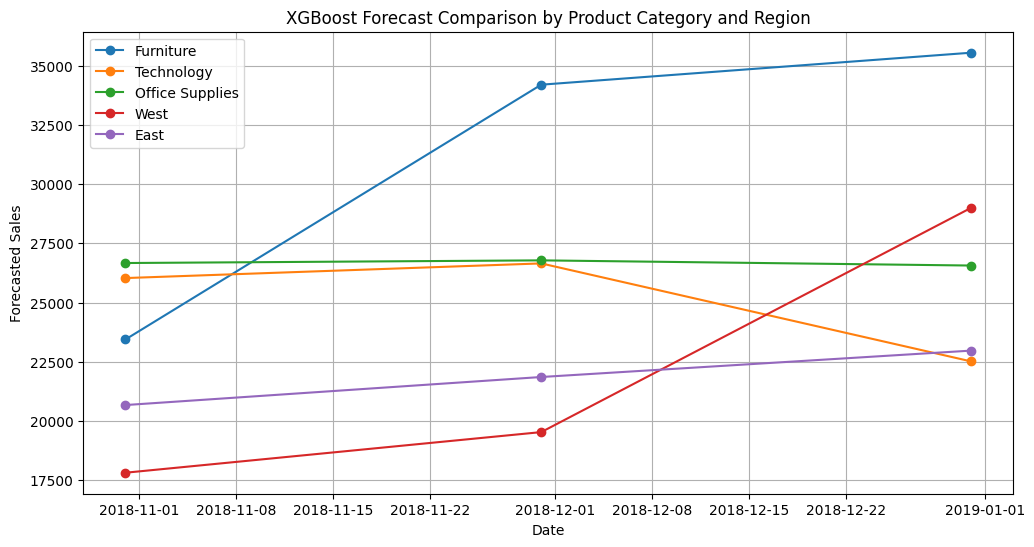

In [77]:
plt.figure(figsize=(12,6))

plt.plot(dates_f, pred_f, marker='o', label='Furniture')

plt.plot(dates_t, pred_t, marker='o', label='Technology')

plt.plot(dates_o, pred_o, marker='o', label='Office Supplies')

plt.plot(dates_w, pred_w, marker='o', label='West')

plt.plot(dates_e, pred_e, marker='o', label='East')

plt.title("XGBoost Forecast Comparison by Product Category and Region")

plt.xlabel("Date")

plt.ylabel("Forecasted Sales")

plt.legend()

plt.grid(True)

plt.show()

## Observations:
The **XGBoost model** was applied separately to forecast monthly sales for **three product** categories and **two regions**.
Among the **product categories, Furniture** is predicted to experience the **strongest sales growth** over the next three months.
Among the regions, the **West region** shows the **highest projected growth**, with a significant increase in forecasted sales by the final month.
**Technology** shows a declining trend toward the end of the forecast period, while **Office Supplies** remains relatively stable and the **East region** exhibits moderate growth.

## Task-5 Anomaly Detection in Sales Data

In [78]:
weekly_sales = df.resample('W', on='Order Date')['Sales'].sum()
weekly_sales = weekly_sales.to_frame()
weekly_sales.head()

,Sales
Order Date,
2015-01-04,304.508
2015-01-11,4619.108
2015-01-18,4130.533
2015-01-25,3092.544
2015-02-01,2527.914


In [79]:
from sklearn.ensemble import IsolationForest
iso = IsolationForest(
    contamination=0.03,
    random_state=42
)
weekly_sales['Anomaly_IF'] = iso.fit_predict(weekly_sales[['Sales']])
if_anomalies = weekly_sales[weekly_sales['Anomaly_IF'] == -1]

In [80]:
if_anomalies.to_csv("saved_outputs/if_anomalies.csv")

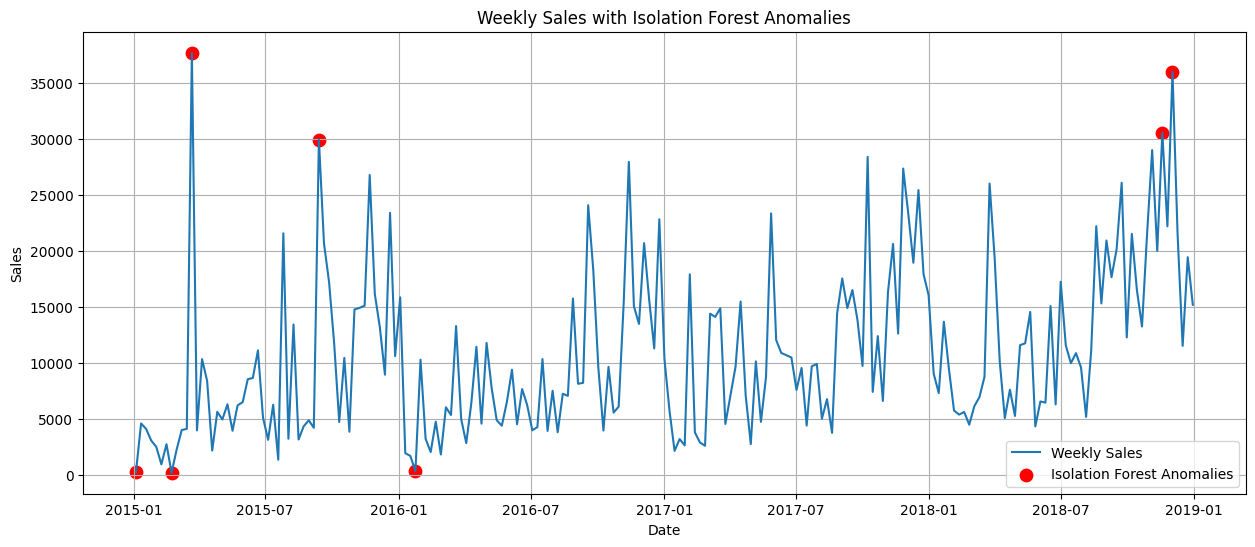

In [81]:
plt.figure(figsize=(15,6))

plt.plot(
    weekly_sales.index,
    weekly_sales['Sales'],
    label='Weekly Sales'
)

plt.scatter(
    if_anomalies.index,
    if_anomalies['Sales'],
    color='red',
    marker='o',
    s=80,
    label='Isolation Forest Anomalies'
)

plt.title("Weekly Sales with Isolation Forest Anomalies")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()

plt.grid(True)

plt.savefig(
    "saved_outputs/isolation_forest_anomalies.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Observations (Isolation Forest)

Isolation Forest detected the following anomalous weeks:

**2015-01-04**: Extremely low sales, likely because this is the beginning of the dataset or a week with very low business activity.

**2015-02-22**: Another unusually low sales week, possibly due to reduced customer demand or operational factors.

**2015-03-22**: Exceptionally high sales, which may correspond to a promotional campaign, bulk purchase, or seasonal event.

**2015-09-13**: Significant sales spike, possibly due to discounts or a major customer order.

**2016-01-24**: Very low sales, which could be explained by the post-holiday decline in customer spending.

**2018-11-18**: High sales during the festive shopping season, likely influenced by pre-holiday promotions.

**2018-12-02**: Another major sales spike, likely associated with year-end holiday shopping.

In [82]:
window = 8
weekly_sales['Rolling_Mean'] = weekly_sales['Sales'].rolling(window=window).mean()
weekly_sales['Rolling_STD'] = weekly_sales['Sales'].rolling(window=window).std()

In [83]:
weekly_sales['Rolling_Z'] = (
    (weekly_sales['Sales'] - weekly_sales['Rolling_Mean'])
    /
    weekly_sales['Rolling_STD']
)

In [84]:
weekly_sales['Anomaly_Z'] = (
    weekly_sales['Rolling_Z'].abs() > 2
)

In [85]:
z_anomalies = weekly_sales[
    weekly_sales['Anomaly_Z']
]
weekly_sales[['Sales', 'Rolling_Mean', 'Rolling_STD', 'Rolling_Z', 'Anomaly_Z']].tail(10)

,Sales,Rolling_Mean,Rolling_STD,Rolling_Z,Anomaly_Z
Order Date,,,,,
2018-10-28,21535.2700,18636.282150,4619.248633,0.627589,False
2018-11-04,29017.4670,20054.459525,5856.762152,1.530369,False
2018-11-11,20015.5500,20035.628150,5856.593734,-0.003428,False
2018-11-18,30572.4470,20594.129900,6674.007114,1.495101,False
2018-11-25,22212.7690,21833.718275,5772.669891,0.065663,False
2018-12-02,35998.9000,23641.631525,7631.524060,1.619240,False
2018-12-09,21537.2410,24270.057775,7152.298738,-0.382089,False
2018-12-16,11542.8340,24054.059750,7547.121999,-1.657748,False
2018-12-23,19457.0680,23794.284500,7680.787898,-0.564684,False


In [86]:
z_anomalies.to_csv("saved_outputs/z_anomalies.csv")

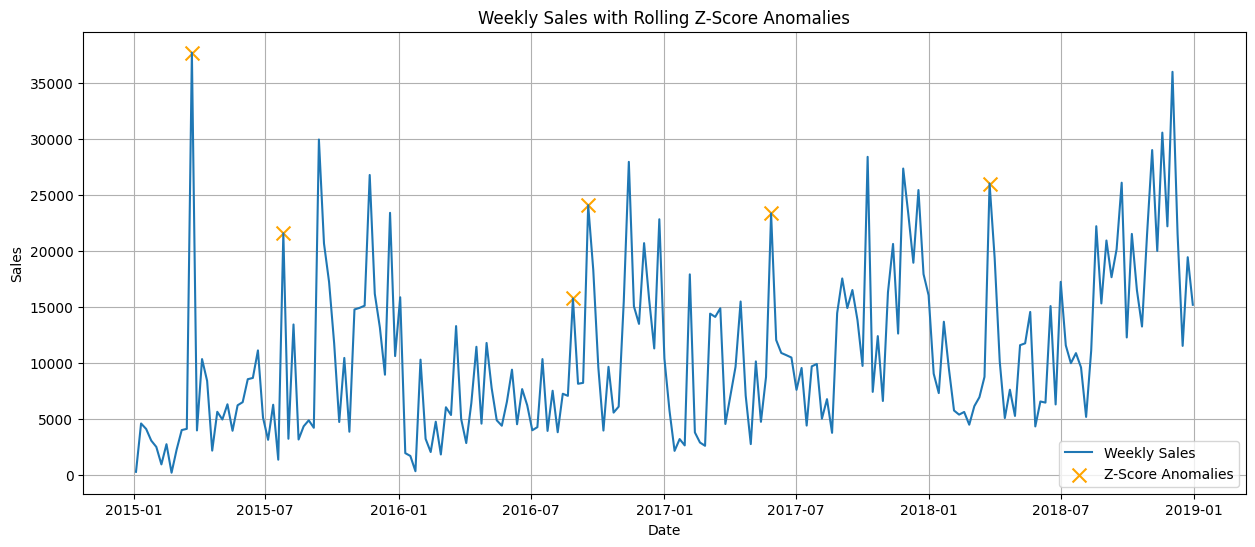

In [87]:
plt.figure(figsize=(15,6))

plt.plot(
    weekly_sales.index,
    weekly_sales['Sales'],
    label='Weekly Sales'
)

plt.scatter(
    z_anomalies.index,
    z_anomalies['Sales'],
    color='orange',
    marker='x',
    s=100,
    label='Z-Score Anomalies'
)

plt.title("Weekly Sales with Rolling Z-Score Anomalies")

plt.xlabel("Date")

plt.ylabel("Sales")

plt.legend()

plt.grid(True)

plt.savefig(
    "saved_outputs/zscore_anomalies.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Observations (Rolling Z-Score)

Rolling Z-Score identified these anomalous weeks:

**2015-03-22**: Strong positive deviation from the recent rolling average, indicating an exceptional sales spike.

**2015-07-26**: Higher-than-usual sales compared to surrounding weeks, possibly due to a seasonal promotion.

**2016-08-28**: Temporary increase in weekly sales, which may reflect a marketing campaign or increased seasonal demand.

**2016-09-18**: Another local sales surge compared with recent weeks.

**2017-05-28**: Sales increased significantly relative to the rolling trend, possibly due to promotional activities.

**2018-03-25**: Higher-than-expected weekly sales, which may be linked to seasonal purchasing behavior.

In [88]:
print(f"Isolation Forest anomalies: {len(if_anomalies)}")
print(f"Rolling Z-Score anomalies: {len(z_anomalies)}")
common = if_anomalies.index.intersection(z_anomalies.index)
print(f"Common anomalies: {len(common)}")

Isolation Forest anomalies: 7
Rolling Z-Score anomalies: 6
Common anomalies: 1


In [89]:
common = if_anomalies.index.intersection(z_anomalies.index)

print("Common anomalies:", len(common))
print("Common anomaly dates:")
print(common)

only_if = if_anomalies.index.difference(z_anomalies.index)
only_z = z_anomalies.index.difference(if_anomalies.index)

print("Only Isolation Forest:")
print(only_if)

print("\nOnly Z-Score:")
print(only_z)

Common anomalies: 1
Common anomaly dates:
DatetimeIndex(['2015-03-22'], dtype='datetime64[ns]', name='Order Date', freq=None)
Only Isolation Forest:
DatetimeIndex(['2015-01-04', '2015-02-22', '2015-09-13', '2016-01-24',
               '2018-11-18', '2018-12-02'],
              dtype='datetime64[ns]', name='Order Date', freq=None)

Only Z-Score:
DatetimeIndex(['2015-07-26', '2016-08-28', '2016-09-18', '2017-05-28',
               '2018-03-25'],
              dtype='datetime64[ns]', name='Order Date', freq=None)


## Comparison of the Two Methods

**Isolation Forest** detected 7 anomalous weeks, whereas the **Rolling Z-Score** method detected 6 anomalous weeks. However, **only one week** (22 March 2015) was identified by **both** methods.

This difference occurs because the two techniques use different approaches to detect anomalies. **Isolation Forest** is a machine learning algorithm that identifies observations that are unusual with respect to the overall data distribution, allowing it to detect both unusually high and unusually low sales weeks. In contrast, the **Rolling Z-Score** method compares each week's sales with the recent 8-week rolling average and flags weeks that deviate by more than two standard deviations. As a result, it is more sensitive to local changes in sales patterns.

The **fact** that only one anomaly was common between the two methods suggests that each technique captures **different types** of unusual behavior. Using both methods together provides a more comprehensive analysis of anomalous sales patterns.

## Task 6 — Product Demand Segmentation using Clustering

## Total sales volume

In [90]:
total_sales = (
    df.groupby('Sub-Category')['Sales']
      .sum()
      .sort_values(ascending=False)
)

total_sales

Sub-Category
Phones         327782.4480
Chairs         322822.7310
Storage        219343.3920
Tables         202810.6280
Binders        200028.7850
Machines       189238.6310
Accessories    164186.7000
Copiers        146248.0940
Bookcases      113813.1987
Appliances     104618.4030
Furnishings     89212.0180
Paper           76828.3040
Supplies        46420.3080
Art             26705.4100
Envelopes       16128.0460
Labels          12347.7260
Fasteners        3001.9600
Name: Sales, dtype: float64

## Sales growth rate (year-over-year)

In [91]:
yearly_sales = (
    df.groupby(['Sub-Category', 'Year'])['Sales']
      .sum()
      .reset_index()
)

yearly_sales.head()

,Sub-Category,Year,Sales
0,Accessories,2015,23766.396
1,Accessories,2016,40443.970
2,Accessories,2017,41735.364
3,Accessories,2018,58240.970
4,Appliances,2015,15160.715


In [92]:
sales_pivot = yearly_sales.pivot(
    index='Sub-Category',
    columns='Year',
    values='Sales'
).fillna(0)

sales_pivot

Year,2015,2016,2017,2018
Sub-Category,,,,
Accessories,23766.3960,40443.9700,41735.3640,58240.9700
Appliances,15160.7150,23228.1790,26016.7870,40212.7220
Art,5897.5340,6091.6360,5890.6080,8825.6320
Binders,43263.2670,36049.7460,48994.5170,71721.2550
Bookcases,20036.6776,37476.7749,26275.4665,30024.2797
Chairs,77046.4400,70654.6730,81930.3450,93191.2730
Copiers,10849.7820,26179.4500,46319.4740,62899.3880
Envelopes,3844.5900,4448.2180,4456.6640,3378.5740
Fasteners,655.3880,545.2240,946.2740,855.0740


In [93]:
sales_pivot['Growth_Rate'] = (
    (sales_pivot[2018] - sales_pivot[2015])
    / sales_pivot[2015]
) * 100

sales_pivot[['Growth_Rate']]

Year,Growth_Rate
Sub-Category,
Accessories,145.055961
Appliances,165.242912
Art,49.649531
Binders,65.778638
Bookcases,49.846598
Chairs,20.954677
Copiers,479.729510
Envelopes,-12.121345
Fasteners,30.468364


## Sales volatility (standard deviation of monthly sales)

In [94]:
df['YearMonth'] = df['Order Date'].dt.to_period('M')

In [95]:
monthly_sales = (
    df.groupby(['Sub-Category', 'YearMonth'])['Sales']
      .sum()
      .reset_index()
)

monthly_sales.head()

,Sub-Category,YearMonth,Sales
0,Accessories,2015-01,827.890
1,Accessories,2015-02,1120.990
2,Accessories,2015-03,957.734
3,Accessories,2015-04,2323.700
4,Accessories,2015-05,695.490


In [96]:
volatility = (
    monthly_sales.groupby('Sub-Category')['Sales']
    .std()
)

volatility

Sub-Category
Accessories    2579.994809
Appliances     1821.621539
Art             330.488343
Binders        3848.223648
Bookcases      2220.405080
Chairs         4407.232960
Copiers        5500.774391
Envelopes       228.218688
Fasteners        48.742229
Furnishings    1360.017867
Labels          223.471218
Machines       5603.554747
Paper          1024.824982
Phones         4052.718221
Storage        2822.084310
Supplies       2025.094139
Tables         3224.082504
Name: Sales, dtype: float64

## Average Order Value

In [97]:
avg_order = (
    df.groupby('Sub-Category')['Sales']
      .mean()
)

avg_order

Sub-Category
Accessories     217.178175
Appliances      227.926804
Art              34.019631
Binders         134.067550
Bookcases       503.598224
Chairs          531.833165
Copiers        2215.880212
Envelopes        65.032444
Fasteners        14.027850
Furnishings      95.823865
Labels           34.587468
Machines       1645.553313
Paper            57.420257
Phones          374.180877
Storage         263.633885
Supplies        252.284283
Tables          645.893720
Name: Sales, dtype: float64

In [98]:
#Create the Feature Table
cluster_data = pd.DataFrame({
    'Total_Sales': total_sales,
    'Growth_Rate': sales_pivot['Growth_Rate'],
    'Volatility': volatility,
    'Average_Order_Value': avg_order
})

cluster_data

,Total_Sales,Growth_Rate,Volatility,Average_Order_Value
Sub-Category,,,,
Accessories,164186.7000,145.055961,2579.994809,217.178175
Appliances,104618.4030,165.242912,1821.621539,227.926804
Art,26705.4100,49.649531,330.488343,34.019631
Binders,200028.7850,65.778638,3848.223648,134.067550
Bookcases,113813.1987,49.846598,2220.405080,503.598224
Chairs,322822.7310,20.954677,4407.232960,531.833165
Copiers,146248.0940,479.729510,5500.774391,2215.880212
Envelopes,16128.0460,-12.121345,228.218688,65.032444
Fasteners,3001.9600,30.468364,48.742229,14.027850


In [99]:
cluster_data.isnull().sum()

Total_Sales            0
Growth_Rate            0
Volatility             0
Average_Order_Value    0
dtype: int64

In [100]:
# Standardize the Features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(cluster_data)

In [101]:
scaled_features

array([[ 0.31598599,  0.60316135,  0.08508503, -0.36354857],
       [-0.28817617,  0.78345815, -0.34706199, -0.34520236],
       [-1.07839653, -0.24894717, -1.19676068, -0.67617125],
       [ 0.67950874, -0.10489242,  0.80776519, -0.50540527],
       [-0.19491939, -0.2471871 , -0.11982149,  0.12532518],
       [ 1.92492716, -0.50523105,  1.12630781,  0.17351776],
       [ 0.13404648,  3.59224905,  1.74944512,  3.04791985],
       [-1.18567579, -0.80064468, -1.25503743, -0.62323728],
       [-1.31880507, -0.42026095, -1.35730925, -0.71029406],
       [-0.44443302,  0.26170686, -0.61009955, -0.57068119],
       [-1.2240171 , -0.37020064, -1.2577427 , -0.67520204],
       [ 0.57007129, -0.95847755,  1.80801288,  2.07446199],
       [-0.57003291,  0.12842429, -0.80110392, -0.63623008],
       [ 1.97523032, -0.37480712,  0.92429319, -0.09556978],
       [ 0.87540412, -0.34972341,  0.22303591, -0.28425602],
       [-0.87844126, -0.59167439, -0.23111635, -0.30362799],
       [ 0.70772315, -0.

In [102]:
from sklearn.cluster import KMeans

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_features)

    wcss.append(kmeans.inertia_)

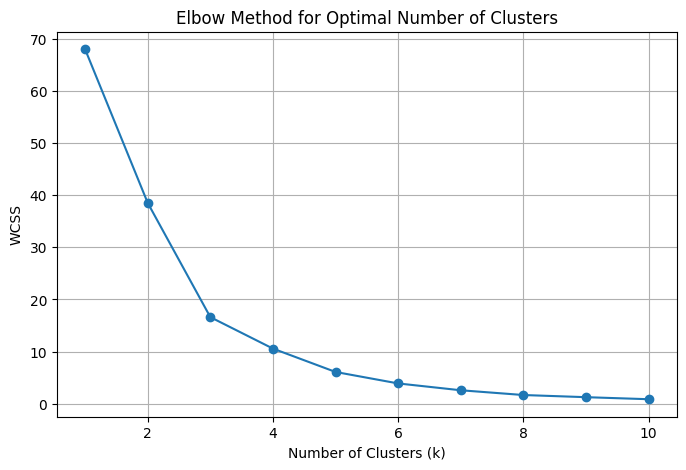

In [103]:
plt.figure(figsize=(8,5))

plt.plot(range(1,11), wcss, marker='o')

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")

plt.grid(True)

plt.show()

## Observation: 
The Elbow Method suggests using 4 clusters. WCSS decreases rapidly from k = 1 to k = 4, indicating that each additional cluster significantly improves cluster compactness. After k = 4, the curve begins to flatten, and further increases in the number of clusters produce only marginal reductions in WCSS. Therefore, k = 4 provides a good balance between model simplicity and clustering performance.

In [104]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_data['Cluster'] = kmeans.fit_predict(scaled_features)

In [105]:
cluster_data.to_csv(
    "saved_outputs/cluster_results.csv"
)

In [106]:
cluster_summary = (
    cluster_data
    .groupby('Cluster')
    .mean(numeric_only=True)
)

cluster_summary

,Total_Sales,Growth_Rate,Volatility,Average_Order_Value
Cluster,,,,
0,239495.780667,56.465168,3489.056075,361.131228
1,146248.094000,479.729510,5500.774391,2215.880212
2,54341.708189,58.795823,1031.431565,142.746758
3,189238.631000,-29.793120,5603.554747,1645.553313


In [107]:
cluster_data.reset_index()[['Sub-Category', 'Cluster']].sort_values('Cluster')

,Sub-Category,Cluster
0,Accessories,0
14,Storage,0
13,Phones,0
5,Chairs,0
16,Tables,0
3,Binders,0
6,Copiers,1
7,Envelopes,2
15,Supplies,2
9,Furnishings,2


In [108]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_features = pca.fit_transform(scaled_features)

cluster_data['PC1'] = pca_features[:,0]
cluster_data['PC2'] = pca_features[:,1]

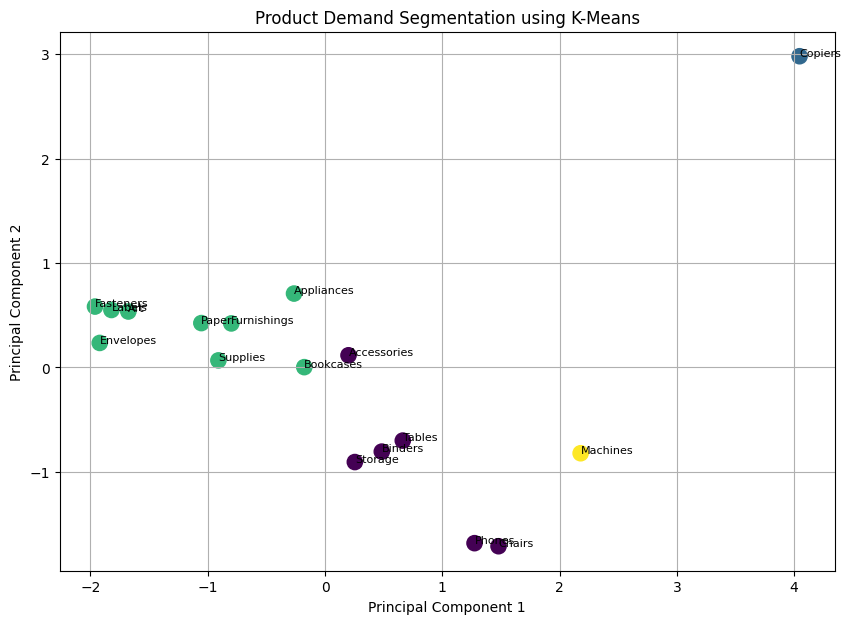

In [109]:
plt.figure(figsize=(10,7))

plt.scatter(
    cluster_data['PC1'],
    cluster_data['PC2'],
    c=cluster_data['Cluster'],
    cmap='viridis',
    s=120
)

for subcat, row in cluster_data.iterrows():
    plt.text(
        row['PC1'],
        row['PC2'],
        subcat,
        fontsize=8
    )

plt.title("Product Demand Segmentation using K-Means")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.savefig(
    "saved_outputs/cluster_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## PCA Visualization Observations
The PCA plot projects the four-dimensional product features into two principal components for visualization.

Copiers form a separate cluster because of their exceptionally high growth rate and average order value.

Machines also appear as an isolated cluster due to their declining demand and high sales volatility.

Most remaining sub-categories are grouped into two larger clusters representing products with either high-volume stable demand or lower-volume stable demand.

The visible separation between clusters indicates that K-Means successfully identified distinct demand patterns among product sub-categories.

## Cluster Analysis

The **K-Means algorithm** grouped the product sub-categories into **4 distinct** demand segments based on **four features: Total Sales, Sales Growth Rate, Sales Volatility, and Average Order Value**.

**Cluster 0 – High Volume, Stable Demand**

**Sub-Categories**: Accessories, Binders, Chairs, Phones, Storage, Tables

**Characteristics**:
Highest total sales among the multi-product clusters.
Moderate positive sales growth.
Moderate sales volatility.
Represents the core revenue-generating products with relatively stable demand.

**Cluster 1 – Growing Demand (Premium Products)**

**Sub-Category**: Copiers

**Characteristics**:
Highest sales growth rate (479.73%).
Highest average order value.
High sales volatility due to rapidly increasing demand.
Represents a premium product with strong growth potential.

**Cluster 2 – Low Volume, Stable Demand**

**Sub-Categories**: Appliances, Art, Bookcases, Envelopes, Fasteners, Furnishings, Labels, Paper, Supplies

**Characteristics**:
Lower sales volume.
Lower average order value.
Comparatively low sales volatility.
Represents products with consistent but relatively lower demand.

**Cluster 3 – Declining Demand**

**Sub-Category**: Machines

**Characteristics**:
Negative sales growth (-29.79%).
Highest sales volatility.
High average order value but declining demand over time.
Indicates a product category requiring closer business attention.

## **Recommended Stocking Strategy**

**FOR-High Volume, Stable Demand**	: Maintain higher inventory levels and prioritize timely replenishment to avoid stock-outs.

**FOR-Growing Demand (Premium Products)** :	Increase inventory gradually based on demand forecasts and ensure sufficient stock during promotional periods.

**FOR-Low Volume, Stable Demand** :	Maintain moderate inventory levels and replenish based on actual demand to avoid unnecessary inventory costs.

**FOR-Declining Demand** :	Reduce inventory levels, avoid overstocking, and consider promotional discounts or clearance strategies to minimize excess stock.

## TASK-7 Preparation

In [110]:
def create_monthly_ts(df, filter_type=None, filter_value=None):
    """
    Creates a monthly time series (monthly_ts) for overall sales
    or for a selected Category/Region.
    """

    filtered_df = df.copy()

    # Apply filter if selected
    if filter_type is not None and filter_value is not None:
        filtered_df = filtered_df[
            filtered_df[filter_type] == filter_value
        ]

    # Aggregate monthly sales
    monthly_ts = (
        filtered_df
        .groupby(pd.Grouper(key="Order Date", freq="ME"))["Sales"]
        .sum()
        .to_frame()
    )

    # Ensure chronological order
    monthly_ts.sort_index(inplace=True)

    return monthly_ts

In [111]:
overall_sales = create_monthly_ts(df)

overall_sales.head()

,Sales
Order Date,
2015-01-31,14205.707
2015-02-28,4519.892
2015-03-31,55205.797
2015-04-30,27906.855
2015-05-31,23644.303


In [112]:
print(overall_sales.equals(monthly_sales))

False


In [113]:
print(monthly_sales.dtypes)
print()
print(overall_sales.dtypes)

Sub-Category       object
YearMonth       period[M]
Sales             float64
dtype: object

Sales    float64
dtype: object


In [114]:
print(monthly_ts.head())
print(monthly_ts.dtypes)

                Sales
Order Date           
2015-01-31  14205.707
2015-02-28   4519.892
2015-03-31  55205.797
2015-04-30  27906.855
2015-05-31  23644.303
Sales    float64
dtype: object


In [115]:
monthly_ts_test = create_monthly_ts(df)

monthly_ts_test.head()

,Sales
Order Date,
2015-01-31,14205.707
2015-02-28,4519.892
2015-03-31,55205.797
2015-04-30,27906.855
2015-05-31,23644.303


In [116]:
tech_ts = create_monthly_ts(
    df,
    filter_type="Category",
    filter_value="Technology"
)

tech_ts.head()

,Sales
Order Date,
2015-01-31,3143.290
2015-02-28,1608.510
2015-03-31,32359.974
2015-04-30,8973.144
2015-05-31,9599.876


In [117]:
west_ts = create_monthly_ts(
    df,
    filter_type="Region",
    filter_value="West"
)

west_ts.head()

,Sales
Order Date,
2015-01-31,2938.723
2015-02-28,1057.956
2015-03-31,11008.898
2015-04-30,9070.357
2015-05-31,6570.438


In [118]:
def prepare_features(monthly_ts):
    """
    Convert monthly time series into ML-ready features.
    """

    ts_ml = monthly_ts.copy().reset_index()

    # Lag Features
    ts_ml["Lag_1"] = ts_ml["Sales"].shift(1)
    ts_ml["Lag_2"] = ts_ml["Sales"].shift(2)
    ts_ml["Lag_3"] = ts_ml["Sales"].shift(3)

    # Rolling Mean
    ts_ml["Rolling_Mean_3"] = ts_ml["Sales"].shift(1).rolling(window=3).mean()

    # Calendar Features
    ts_ml["Month"] = ts_ml["Order Date"].dt.month
    ts_ml["Quarter"] = ts_ml["Order Date"].dt.quarter

    # Season Feature
    def get_season(month):
        if month in [12, 1, 2]:
            return "Winter"
        elif month in [3, 4, 5]:
            return "Spring"
        elif month in [6, 7, 8]:
            return "Summer"
        else:
            return "Autumn"

    ts_ml["Season"] = ts_ml["Month"].apply(get_season)

    # One-hot encoding
    ts_ml = pd.get_dummies(
        ts_ml,
        columns=["Season"],
        drop_first=True
    )

    # Remove rows with missing lag values
    ts_ml = ts_ml.dropna()

    return ts_ml

In [119]:
tech_features = prepare_features(tech_ts)

tech_features.head()

,Order Date,Sales,Lag_1,Lag_2,Lag_3,Rolling_Mean_3,Month,Quarter,Season_Spring,Season_Summer,Season_Winter
3,2015-04-30,8973.144,32359.974,1608.510,3143.290,14313.876000,4,2,True,False,False
4,2015-05-31,9599.876,8973.144,32359.974,1608.510,16977.664667,5,2,True,False,False
5,2015-06-30,8435.965,9599.876,8973.144,32359.974,9002.995000,6,2,False,True,False
6,2015-07-31,7839.284,8435.965,9599.876,8973.144,8625.041667,7,3,False,True,False
7,2015-08-31,8937.050,7839.284,8435.965,9599.876,8404.099667,8,3,False,True,False


In [120]:
def prepare_train_test(ts_ml):
    """
    Prepare training and testing datasets
    for XGBoost forecasting.
    """

    X = ts_ml.drop(columns=["Order Date", "Sales"])
    y = ts_ml["Sales"]

    X_train = X.iloc[:-3]
    X_test = X.iloc[-3:]

    y_train = y.iloc[:-3]
    y_test = y.iloc[-3:]

    return X_train, X_test, y_train, y_test

In [121]:
X_train, X_test, y_train, y_test = prepare_train_test(tech_features)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (42, 9)
X_test shape : (3, 9)
y_train shape: (42,)
y_test shape : (3,)


## Testing the UI data/feature display

In [122]:
print("Total Sales:", df["Sales"].sum())
print("Total Orders:", df["Order ID"].nunique())
print("Average Order Value:", df["Sales"].mean())
print("Regions:", df["Region"].nunique())

Total Sales: 2261536.7827000003
Total Orders: 4922
Average Order Value: 230.7690594591837
Regions: 4


In [123]:
print("Categories:")
print(df["Category"].value_counts())

print("\nRegions:")
print(df["Region"].value_counts())

Categories:
Category
Office Supplies    5909
Furniture          2078
Technology         1813
Name: count, dtype: int64

Regions:
Region
West       3140
East       2785
Central    2277
South      1598
Name: count, dtype: int64


In [124]:
category_sales = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

print(category_sales)

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


In [125]:
region_sales = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)

print(region_sales)

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64
